In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import json
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"
##################################################################

import logging
from src.utils import logging_utils
from src.utils import env_utils, experiment_utils
import torch
import transformers
from rich.console import Console
from rich.theme import Theme
import nnsight

experiment_utils.set_seed(42)

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, width=300)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")
logger.info(f"{nnsight.__version__}")


2026-03-03 13:19:56 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-03-03 13:19:57 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=8, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-03-03 13:19:57 __main__ INFO     transformers.__version__='5.1.0'
2026-03-03 13:19:57 __main__ INFO     0.5.15


## Load Model

In [3]:
from src.models import ModelandTokenizer

# model_key = "Qwen/Qwen2.5-Coder-14B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-32B"
model_key = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=model_key,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)


2026-03-03 13:20:01 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-03 13:20:01 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-03 13:20:02 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe6c692ca10>
2026-03-03 13:20:02 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fe6c69300d0> server_hostname='huggingface.co' timeout=10
2026-03-03 13:20:02 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe6c692c920>
2026-03-03 13:20:02 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-03 13:20:02 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-03 13:20:02 http

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-03 13:20:23 httpcore.connection DEBUG    close.started
2026-03-03 13:20:23 httpcore.connection DEBUG    close.complete
2026-03-03 13:20:23 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-03 13:20:23 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe6c5446870>
2026-03-03 13:20:23 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fe6c69300d0> server_hostname='huggingface.co' timeout=10
2026-03-03 13:20:23 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe6c39dfa10>
2026-03-03 13:20:23 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-03 13:20:23 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-03 13:20:23 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Load Multi-Predicate Data

In [5]:
from src.goals.predicate_data import MultiPredicateDataset
from src.goals.predicate_sampling import MCTSSearchResults_for_TargetPredicate

# ── Select target predicate ──────────────────────────────────────────────────
PREDICATE_IDX = 2

eval_dataset = MultiPredicateDataset.load_dataset()
target_predicate = eval_dataset[PREDICATE_IDX]
rich_print(f"Target predicate : [cyan]{target_predicate.name}[/cyan]")
rich_print(f"P+ : [bold green]{target_predicate.p_plus.description}[/bold green]  anchors={target_predicate.p_plus.anchor_tokens}")
for i, s in enumerate(target_predicate.samples):
    p_minus_desc = s.p_minus.description if s.p_minus else "(none)"
    rich_print(f"  Sample {i} — fn=[yellow]{s.function_name}[/yellow]  P-: {p_minus_desc}")


2026-03-03 13:20:41 src.goals.predicate_data INFO     Loaded TargetPredicate 'has_unique_elements' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/has_unique_elements.json
2026-03-03 13:20:41 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_anagram' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_anagram.json
2026-03-03 13:20:41 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_palindrome' with 5 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_palindrome.json


2026-03-03 13:20:41 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_perfect_square' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_perfect_square.json
2026-03-03 13:20:41 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_power_of_two' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_power_of_two.json
2026-03-03 13:20:41 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_sorted' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_sorted.json
2026-03-03 13:20:41 src.goals.predicate_data INFO     Loaded MultiPredicateDataset: 6 target predicate(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate


Target predicate : is_palindrome

P+ : check whether s is a palindrome (s == s[::-1])  anchors=['::-1]', '== s.lower()[::-1]', '== s[', '== s[::-1]', '==s', '>> 1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s', 's != s[', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 
's.lower()[::-1]', 's[-(', 's[-1:-3:-1]', 's[-2:]', 's[-i-1]', 's[::-', 's[::- 1]', 's[::-1]']

Sample 0 — fn=is_valid_palindrome  P-: check whether len(s) >= 2

Sample 1 — fn=is_alpha_palindrome  P-: check whether s.isalpha() (all characters are alphabetic)

Sample 2 — fn=is_spaceless_palindrome  P-: check whether ' ' not in s (no spaces)

Sample 3 — fn=is_upper_palindrome  P-: check whether s is non-empty and s[0].isupper()

Sample 4 — fn=is_lowercase_palindrome  P-: check whether s == s.lower() (all lowercase)

In [6]:
model_tag = mt.name.split("/")[-1]
TREE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_mcts",
    model_tag,
    target_predicate.name,
)

# Load MCTS results — supports both new per-sample layout and legacy single-file
tp_results = MCTSSearchResults_for_TargetPredicate.load(TREE_DIR)
rich_print(f"Loaded [bold]{len(tp_results.sample_results)}[/bold] sample results from {TREE_DIR}")
for i, sr in enumerate(tp_results.sample_results):
    counts = [run.eval_counts for run in sr.runs]
    rich_print(f"  Sample {i} — {len(sr.runs)} runs  eval_counts={counts}")

2026-03-03 13:20:43 src.goals.predicate_sampling INFO     Loaded MCTSSearchResults for sample from /disk/u/arnab/Codes/Projects/goals/results/multipred_mcts/Qwen2.5-Coder-32B-Instruct/is_palindrome/check_whether___not_in_s_no_spaces/mcts.json
2026-03-03 13:20:44 src.goals.predicate_sampling INFO     Loaded MCTSSearchResults for sample from /disk/u/arnab/Codes/Projects/goals/results/multipred_mcts/Qwen2.5-Coder-32B-Instruct/is_palindrome/check_whether_lens__2/mcts.json
2026-03-03 13:20:45 src.goals.predicate_sampling INFO     Loaded MCTSSearchResults for sample from /disk/u/arnab/Codes/Projects/goals/results/multipred_mcts/Qwen2.5-Coder-32B-Instruct/is_palindrome/check_whether_s.isalpha_all_characters_a/mcts.json
2026-03-03 13:20:45 src.goals.predicate_sampling INFO     Loaded MCTSSearchResults for sample from /disk/u/arnab/Codes/Projects/goals/results/multipred_mcts/Qwen2.5-Coder-32B-Instruct/is_palindrome/check_whether_s__s.lower_all_lowercase/mcts.json
2026-03-03 13:20:46 src.goals.p

Loaded 5 sample results from /disk/u/arnab/Codes/Projects/goals/results/multipred_mcts/Qwen2.5-Coder-32B-Instruct/is_palindrome

Sample 0 — 10 runs  eval_counts=[{'green': 14, 'orange': 13, 'red': 3, 'total': 30}, {'green': 12, 'orange': 8, 'red': 10, 'total': 30}, {'green': 50, 'orange': 58, 'red': 12, 'total': 120}, {'green': 14, 'orange': 5, 'red': 3, 'total': 22}, {'green': 6, 'orange': 0, 'red': 3, 'total': 9}, 
{'green': 6, 'orange': 0, 'red': 3, 'total': 9}, {'green': 82, 'orange': 26, 'red': 26, 'total': 134}, {'green': 6, 'orange': 0, 'red': 2, 'total': 8}, {'green': 32, 'orange': 30, 'red': 9, 'total': 71}, {'green': 4, 'orange': 0, 'red': 12, 'total': 16}]

Sample 1 — 10 runs  eval_counts=[{'green': 10, 'orange': 9, 'red': 3, 'total': 22}, {'green': 18, 'orange': 0, 'red': 4, 'total': 22}, {'green': 28, 'orange': 129, 'red': 2, 'total': 159}, {'green': 10, 'orange': 7, 'red': 2, 'total': 19}, {'green': 31, 'orange': 55, 'red': 35, 'total': 121}, 
{'green': 4, 'orange': 0, 'red': 5, 'total': 9}, {'green': 10, 'orange': 2, 'red': 5, 'total': 17}, {'green': 8, 'orange': 0, 'red': 6, 'total': 14}, {'green': 18, 'orange': 68, 'red': 18, 'total': 104}, {'green': 10, 'orange': 13, 'red': 4, 'total': 27}]

Sample 2 — 10 runs  eval_counts=[{'green': 6, 'orange': 22, 'red': 0, 'total': 28}, {'green': 7, 'orange': 9, 'red': 6, 'total': 22}, {'green': 14, 'orange': 20, 'red': 0, 'total': 34}, {'green': 6, 'orange': 15, 'red': 2, 'total': 23}, {'green': 13, 'orange': 4, 'red': 6, 'total': 23}, {'green': 
14, 'orange': 2, 'red': 2, 'total': 18}, {'green': 52, 'orange': 248, 'red': 9, 'total': 309}, {'green': 8, 'orange': 4, 'red': 1, 'total': 13}, {'green': 2, 'orange': 68, 'red': 2, 'total': 72}, {'green': 6, 'orange': 6, 'red': 2, 'total': 14}]

Sample 3 — 11 runs  eval_counts=[{'green': 14, 'orange': 8, 'red': 0, 'total': 22}, {'green': 18, 'orange': 15, 'red': 6, 'total': 39}, {'green': 8, 'orange': 23, 'red': 3, 'total': 34}, {'green': 8, 'orange': 7, 'red': 2, 'total': 17}, {'green': 8, 'orange': 2, 'red': 2, 'total': 12}, {'green': 
28, 'orange': 28, 'red': 6, 'total': 62}, {'green': 0, 'orange': 6, 'red': 6, 'total': 12}, {'green': 186, 'orange': 92, 'red': 24, 'total': 302}, {'green': 34, 'orange': 16, 'red': 0, 'total': 50}, {'green': 66, 'orange': 27, 'red': 1, 'total': 94}, {'green': 18, 'orange': 18, 'red': 1, 'total': 
37}]

Sample 4 — 11 runs  eval_counts=[{'green': 18, 'orange': 30, 'red': 2, 'total': 50}, {'green': 6, 'orange': 30, 'red': 6, 'total': 42}, {'green': 18, 'orange': 21, 'red': 0, 'total': 39}, {'green': 16, 'orange': 21, 'red': 0, 'total': 37}, {'green': 2, 'orange': 15, 'red': 9, 'total': 26}, 
{'green': 0, 'orange': 8, 'red': 2, 'total': 10}, {'green': 6, 'orange': 20, 'red': 2, 'total': 28}, {'green': 44, 'orange': 43, 'red': 7, 'total': 94}, {'green': 36, 'orange': 4, 'red': 4, 'total': 44}, {'green': 8, 'orange': 60, 'red': 7, 'total': 75}, {'green': 20, 'orange': 20, 'red': 7, 
'total': 47}]

In [7]:
from src.goals.anchor import extract_anchor_tokens

# ── Ensure anchor tokens are populated (calls oracle LM if missing) ──────────
FORCE_REEXTRACT_ANCHORS = False

needs = (
    FORCE_REEXTRACT_ANCHORS
    or not target_predicate.p_plus.anchor_tokens
    or any(
        not (s.p_minus and s.p_minus.anchor_tokens)
        for s in target_predicate.samples
    )
)
if needs:
    rich_print("[yellow]Extracting anchor tokens via oracle LM...[/yellow]")
    p_plus_anchors, p_minus_per_sample = extract_anchor_tokens(
        tp=target_predicate,
        completions_per_sample=tp_results.completions_per_sample,
    )
    target_predicate.p_plus.anchor_tokens = sorted(p_plus_anchors)
    for i, s in enumerate(target_predicate.samples):
        if s.p_minus is not None:
            s.p_minus.anchor_tokens = sorted(p_minus_per_sample[i])
    target_predicate.save()
    rich_print(f"Saved anchor tokens → {target_predicate._source_path}")
else:
    rich_print("[green]Anchor tokens already populated — skipping oracle.[/green]")

rich_print(f"P+ anchors: {target_predicate.p_plus.anchor_tokens}")
for i, s in enumerate(target_predicate.samples):
    anchors = s.p_minus.anchor_tokens if s.p_minus else []
    rich_print(f"  P- anchors (sample {i}): {anchors}")

Anchor tokens already populated — skipping oracle.

P+ anchors: ['::-1]', '== s.lower()[::-1]', '== s[', '== s[::-1]', '==s', '>> 1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s', 's != s[', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's.lower()[::-1]', 's[-(', 's[-1:-3:-1]', 's[-2:]', 
's[-i-1]', 's[::-', 's[::- 1]', 's[::-1]']

P- anchors (sample 0): ['> 1', '>= 2', 'len(', 'len(s)']

P- anchors (sample 1): ['.isalpha', '.isalpha()', 'alpha(', 'isalpha', 'isalpha()', 's.isalpha', 's.isalpha()']

P- anchors (sample 2): ['" "', '" " not', "' '", "' ' in", "' ' in s", "' ' not in", 'char == " "', 'isspace', "not ' '", 'not in s', 'set(s)', 'space in s', 'space_char', 'split()', 'str(s)']

P- anchors (sample 3): ['.isupper()', "<= 'Z'", 'islower', 'isupper', 'isupper()', 's[0]', 'upper()']

P- anchors (sample 4): ["'a' <=", '.lower', '.lower()', "< 'a'", "<= 'Z'", "<= 'z'", '== s and', "> 'z'", 'abcdefghijklmnopqrstuvwxyz', 'islower', 'isupper', 'isupper()', 'lower()', 's.lower()', "set('abc", 'set(s)']

## Collect Contrastive Pairs

In [10]:
from src.goals.predicate_probe import (
    collect_labeled_nodes,
    sample_multipred_pairs,
    print_node_label_summary,
    print_pairs_sample,
    pairs_position_histogram,
)

# min_p_green: only keep nodes where at least this fraction of MCTS probability
# mass flows to green (correct) leaves.  Filters out nodes that are on a green
# path by luck but where the model's probability mass mostly flows to failures.
# Set to 0.0 to disable.
MIN_P_GREEN = 0.5

# ── Collect labeled nodes and form pairs PER SAMPLE ──────────────────────────
# Pairing per-sample prevents cross-P- contamination: nodes from different
# (P+, P-) pairs are never paired together.
all_labeled = []
all_pairs_by_pos: dict[int, list] = {}

for sample_idx in range(len(target_predicate.samples)):
    labeled_i = collect_labeled_nodes(
        tp_results=tp_results,
        tp=target_predicate,
        mt=mt,
        sample_indices=[sample_idx],
        min_p_green=MIN_P_GREEN,
    )
    all_labeled.extend(labeled_i)

    if not labeled_i:
        rich_print(f"  [yellow]Sample {sample_idx}: no labeled nodes[/yellow]")
        continue

    # Form pairs within this sample only (cross-tree, same abs_position)
    pairs_i = sample_multipred_pairs(
        labeled_nodes=labeled_i,
        allow_same_tree=False,
        abs_pos_tolerance=0,
    )
    n_pairs_i = sum(len(v) for v in pairs_i.values())
    rich_print(f"  Sample {sample_idx}: {len(labeled_i)} labeled nodes → {n_pairs_i} pairs")

    for pos, pairs in pairs_i.items():
        all_pairs_by_pos.setdefault(pos, []).extend(pairs)

print_node_label_summary(all_labeled)
rich_print(f"\nTotal contrastive pairs (per-sample pairing): [bold]{sum(len(v) for v in all_pairs_by_pos.values())}[/bold]")
pairs_position_histogram(all_pairs_by_pos)
print_pairs_sample(all_pairs_by_pos, n=6)

2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill 's == s': 14 green leaves → 90 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill 's[::-1]': 12 green leaves → 66 labeled nodes (0 dropped by p_green < 0.5).


2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill 's[:': 50 green leaves → 680 labeled nodes (48 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill 's ==': 14 green leaves → 108 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill "' ' not in": 6 green leaves → 30 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill '" " not in': 6 green leaves → 30 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill 'not (': 82 green leaves → 510 labeled nodes (18 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill 'False if': 6 green leaves → 0 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 0, prefill 'True if not': 32 green leaves → 1

Sample 0: 1678 labeled nodes → 352 pairs

2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 1, prefill 's == s': 10 green leaves → 58 labeled nodes (2 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 1, prefill 's[::-1]': 18 green leaves → 120 labeled nodes (4 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 1, prefill 's[:': 28 green leaves → 274 labeled nodes (122 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 1, prefill 's ==': 10 green leaves → 94 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 1, prefill 'len(': 31 green leaves → 177 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 1, prefill 'len(s)': 4 green leaves → 20 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 1, prefill 'not (': 10 green leaves → 66 labeled nod

Sample 1: 985 labeled nodes → 126 pairs

2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 2, prefill 's == s': 6 green leaves → 42 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 2, prefill 's[::-1]': 7 green leaves → 39 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 2, prefill 's[:': 14 green leaves → 126 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 2, prefill 's ==': 6 green leaves → 48 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 2, prefill 's.isalpha()': 13 green leaves → 111 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 2, prefill 's.is': 14 green leaves → 116 labeled nodes (0 dropped by p_green < 0.5).
2026-03-03 13:25:46 src.goals.predicate_probe DEBUG    Sample 2, prefill 'not (': 52 green leaves → 394 labeled n

... (57 outputs left out)

abs_pos=101  (pos depth=1, 'aligned_p_plus'  |  neg depth=1, 'adversarial')

+ first '].'

- first 's'

... 2079 more pairs not shown

In [14]:
from src.goals.probe import compute_outcome_probs

# Look at a specific contrastive pair in detail
if all_pairs_by_pos:
    first_abs_pos = max(all_pairs_by_pos.keys())
    pairs = all_pairs_by_pos[first_abs_pos]

    if pairs:
        pair = pairs[0]
        rich_print(
            f"[bold]Example Contrastive Pair at abs_position={first_abs_pos}:[/bold]"
        )
        rich_print("[bright_cyan]Positive (p_plus):[/bright_cyan]")
        print(
            f"  prefill_type={pair.positive.prefill_type!r}  prefill={pair.positive.prefill!r}"
        )
        print(
            f"  label={pair.positive.label!r}  window={pair.positive.window!r}  depth={pair.positive.depth}  p_green={pair.positive.p_green:.2f}"
        )
        print(
            f"  outcome_probs={compute_outcome_probs(pair.positive.node)}  n_children={len(pair.positive.node.children)}"
        )
        prefill_idx = pair.positive.tree_id.index(pair.positive.prefill)
        rich_print(
            f"[white]{pair.positive.tree_id[:prefill_idx]}[/white][bright_yellow]{pair.positive.prefill}[/bright_yellow][bright_green]{pair.positive.node.get_path_text()}[/bright_green]"
        )

        print()
        rich_print("[bright_magenta]Negative (p_minus):[/bright_magenta]")
        print(
            f"  prefill_type={pair.negative.prefill_type!r}  prefill={pair.negative.prefill!r}"
        )
        print(
            f"  label={pair.negative.label!r}  window={pair.negative.window!r}  depth={pair.negative.depth}  p_green={pair.negative.p_green:.2f}"
        )
        print(
            f"  outcome_probs={compute_outcome_probs(pair.negative.node)}  n_children={len(pair.negative.node.children)}"
        )
        prefill_idx = pair.negative.tree_id.index(pair.negative.prefill)
        rich_print(
            f"[white]{pair.negative.tree_id[:prefill_idx]}[/white][bright_yellow]{pair.negative.prefill}[/bright_yellow][bright_green]{pair.negative.node.get_path_text()}[/bright_green]"
        )
else:
    print(
        "[yellow]No contrastive pairs found. Try adjusting thresholds or running more MCTS iterations.[/yellow]"
    )

Example Contrastive Pair at abs_position=132:

Positive (p_plus):

  prefill_type='aligned_p_plus'  prefill='s[:'
  label='p_plus'  window='second'  depth=21  p_green=0.89
  outcome_probs=OutcomeProbs(green=0.889, red=0.000, uncertain=0.111)  n_children=3


def is_upper_palindrome(s: str) -> bool:
    """Return True iff s is non-empty, starts with an uppercase letter, and is a palindrome."""
    return s[:1] >= 'A' and s[:1] <= 'Z' and s == s[::-1

Negative (p_minus):

  prefill_type='adversarial'  prefill='not ('
  label='p_minus'  window='second'  depth=21  p_green=1.00
  outcome_probs=OutcomeProbs(green=1.000, red=0.000, uncertain=0.000)  n_children=2


def is_upper_palindrome(s: str) -> bool:
    """Return True iff s is non-empty, starts with an uppercase letter, and is a palindrome."""
    return not (len(s) == 0) and s == s[::-1] and s[0].isupper

In [15]:
import random
from collections import defaultdict

# ── Build lookup: prefix → prompt (needed to reconstruct full input text) ────
prefix_to_prompt = {
    run.prefix: run.prompt
    for sr in tp_results.sample_results
    for run in sr.runs
}

# ── Flatten pairs into records ────────────────────────────────────────────────
# Each record: pos_text / neg_text to feed the model + metadata for analysis.
all_pairs = [pair for pairs in all_pairs_by_pos.values() for pair in pairs]

pair_records = []
for pair in all_pairs:
    pos_ln = pair.positive
    neg_ln = pair.negative
    pos_prompt = prefix_to_prompt.get(pos_ln.tree_id, "")
    neg_prompt = prefix_to_prompt.get(neg_ln.tree_id, "")
    pair_records.append({
        "pos_text":       pos_prompt + pos_ln.node.get_path_text(),
        "neg_text":       neg_prompt + neg_ln.node.get_path_text(),
        "abs_position":   pair.abs_position,
        "pos_depth":      pos_ln.depth,
        "neg_depth":      neg_ln.depth,
        "pos_window":     pos_ln.window,
        "neg_window":     neg_ln.window,
        "pos_tree_id":    pos_ln.tree_id,
        "neg_tree_id":    neg_ln.tree_id,
        "pos_prefill_type": pos_ln.prefill_type,
        "neg_prefill_type": neg_ln.prefill_type,
        "sample_idx":     pos_ln.sample_idx,
    })

rich_print(f"Total pair records: [bold]{len(pair_records)}[/bold]")

Total pair records: 2085

In [85]:
# ── Train / test split by tree (prevents latent leakage across the split) ────
# Assign each pair based on the positive node's source tree.
# Trees (prefills) are the natural unit of independence here.
N_TRAIN_PAIRS = 10_000   # max pairs in train set; None = use all
N_TEST_PAIRS  = None     # max pairs in test set;  None = use all

random.seed(42)
all_tree_ids = list({rec["pos_tree_id"] for rec in pair_records})
random.shuffle(all_tree_ids)
n_train_trees = max(1, int(0.7 * len(all_tree_ids)))
train_trees = set(all_tree_ids[:n_train_trees])
test_trees  = set(all_tree_ids[n_train_trees:])

train_idx = [i for i, r in enumerate(pair_records) if r["pos_tree_id"] in train_trees]
test_idx  = [i for i, r in enumerate(pair_records) if r["pos_tree_id"] in test_trees]

if N_TRAIN_PAIRS is not None and len(train_idx) > N_TRAIN_PAIRS:
    train_idx = random.sample(train_idx, N_TRAIN_PAIRS)
if N_TEST_PAIRS is not None and len(test_idx) > N_TEST_PAIRS:
    test_idx = random.sample(test_idx, N_TEST_PAIRS)

n_pairs_total = len(pair_records)
rich_print(
    f"Split: [bold]{len(train_idx)}[/bold] train / [bold]{len(test_idx)}[/bold] test  "
    f"({len(train_trees)} train trees / {len(test_trees)} test trees)"
)


Split: 1855 train / 230 test  (23 train trees / 11 test trees)

## Extract Latents

In [91]:
from src.tokens import prepare_input

@torch.inference_mode()
def get_last_token_latents_batch(
    mt: ModelandTokenizer,
    texts: list[str],
    layers: list[int] | None = None,
) -> dict[int, torch.Tensor]:
    """
    Extract residual stream hidden states at the last token position for a batch of inputs.

    Simplified and batched — no interventions, grabs the last non-padding token's
    residual stream across specified layers.  Each layer stays on its native GPU.

    Args:
        mt:     ModelandTokenizer instance.
        texts:  List of input strings.
        layers: Layer indices to extract. None = all layers.

    Returns:
        Dict mapping layer_idx -> Tensor of shape (batch, hidden_dim).
    """
    if layers is None:
        layers = list(range(mt.n_layer))

    inputs = prepare_input(prompts=texts, tokenizer=mt, padding_side="left")

    layer_saves = {}
    with mt.trace(inputs, scan=False):
        for layer_idx in layers:
            layer_name = mt.layer_name_format.format(layer_idx)
            module = mt
            for attr in layer_name.split("."):
                module = module[int(attr)] if attr.isdigit() else getattr(module, attr)
            output = module.output
            if isinstance(output, tuple) or (hasattr(output, "__len__") and not hasattr(output, "shape")):
                output = output[0]
            layer_saves[layer_idx] = output[:, -1, :].save()

    return {l: layer_saves[l].float() for l in layers}


# Quick sanity check
pair_idx = -1
_sample_texts = [pair_records[pair_idx]["pos_text"], pair_records[pair_idx]["neg_text"]]
_test_hs = get_last_token_latents_batch(mt, _sample_texts, layers=[0, mt.n_layer - 1])
for l, t in _test_hs.items():
    rich_print(f"Layer {l}: shape={list(t.shape)}, device={t.device}")


Layer 0: shape=[2, 5120], device=cuda:0

Layer 63: shape=[2, 5120], device=cuda:7

In [96]:
from src.tokens import prepare_input

print(
    f'Positive ({prepare_input(tokenizer=mt, prompts=_sample_texts[0]).input_ids.shape}): "{_sample_texts[0]}"'
)
print()
print(
    f'Negative ({prepare_input(tokenizer=mt, prompts=_sample_texts[1]).input_ids.shape}): "{_sample_texts[1]}"'
)

Positive (torch.Size([1, 133])): "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff the first character of the string is uppercase and the string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_upper_palindrome(s: str) -> bool:
    """Return True iff s is non-empty, starts with an uppercase letter, and is a palindrome."""
    return 0 < len(s) <= len(s) and s[0].isupper() and s == s[::-"

Negative (torch.Size([1, 133])): "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff the first character of the string is uppercase and the stri

In [22]:
LAYERS_TO_PROBE = list(range(mt.n_layer))
BATCH_SIZE = 32

pos_texts = [pair_records[i]["pos_text"] for i in range(n_pairs_total)]
neg_texts = [pair_records[i]["neg_text"] for i in range(n_pairs_total)]
all_texts = pos_texts + neg_texts  # 2 * n_pairs_total

n_total = len(all_texts)
rich_print(f"Extracting latents for {n_total} texts ({n_pairs_total} pairs) in batches of {BATCH_SIZE}...")

latents_by_layer: dict[int, list[torch.Tensor]] = {l: [] for l in LAYERS_TO_PROBE}

for batch_start in range(0, n_total, BATCH_SIZE):
    batch_texts = all_texts[batch_start : batch_start + BATCH_SIZE]
    if batch_start % (BATCH_SIZE * 10) == 0:
        rich_print(f"  Batch {batch_start // BATCH_SIZE + 1}/{(n_total + BATCH_SIZE - 1) // BATCH_SIZE}...")
    batch_hs = get_last_token_latents_batch(mt, batch_texts, layers=LAYERS_TO_PROBE)
    for l in LAYERS_TO_PROBE:
        latents_by_layer[l].append(batch_hs[l])

Z_pos_by_layer: dict[int, torch.Tensor] = {}
Z_neg_by_layer: dict[int, torch.Tensor] = {}

for l in LAYERS_TO_PROBE:
    all_l = torch.cat(latents_by_layer[l], dim=0)   # (2*n_pairs_total, hidden_dim)
    Z_pos_by_layer[l] = all_l[:n_pairs_total]
    Z_neg_by_layer[l] = all_l[n_pairs_total:]

rich_print(f"Done. Z_pos shape (layer 0): {list(Z_pos_by_layer[0].shape)}")


Extracting latents for 4170 texts (2085 pairs) in batches of 32...

Batch 1/131...

Batch 11/131...

Batch 21/131...

Batch 31/131...

Batch 41/131...

... (6 outputs left out)

Batch 111/131...

Batch 121/131...

Batch 131/131...

Done. Z_pos shape (layer 0): [2085, 5120]

In [23]:
# ── (Optional) Save / reload latents to avoid re-extracting ─────────────────
# SAVE_DIR was defined in the loading cell above
save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe_test",
    model_tag,
    target_predicate.name,
)
os.makedirs(save_dir, exist_ok=True)

torch.save(Z_pos_by_layer, os.path.join(save_dir, "Z_pos_by_layer.pt"))
torch.save(Z_neg_by_layer, os.path.join(save_dir, "Z_neg_by_layer.pt"))

Z_pos_by_layer = torch.load(os.path.join(save_dir, "Z_pos_by_layer.pt"))
Z_neg_by_layer = torch.load(os.path.join(save_dir, "Z_neg_by_layer.pt"))
rich_print(f"Save dir: {save_dir}")

Save dir: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe_test/Qwen2.5-Coder-32B-Instruct/is_palindrome

## Analysis of the Latents
### PCA (without goal-specific engineering)

In [24]:
from sklearn.decomposition import PCA
import numpy as np

LAYER_FROM = 0
LAYER_TO   = mt.n_layer
LAYER_STEP = 4

pca_layers = list(range(LAYER_FROM, LAYER_TO, LAYER_STEP))
pca_results: dict[int, dict] = {}

for layer_idx in pca_layers:
    z_pos = Z_pos_by_layer[layer_idx].cpu().numpy()
    z_neg = Z_neg_by_layer[layer_idx].cpu().numpy()
    n = z_pos.shape[0]

    all_z = np.concatenate([z_pos, z_neg], axis=0)
    pca = PCA(n_components=2)
    all_2d = pca.fit_transform(all_z)

    pca_results[layer_idx] = {
        "pos_2d": all_2d[:n],
        "neg_2d": all_2d[n:],
        "explained_variance_ratio": pca.explained_variance_ratio_,
    }

rich_print(f"Computed PCA for {len(pca_layers)} layers: {pca_layers[0]}..{pca_layers[-1]} (step={LAYER_STEP})")
rich_print(f"Latents per layer: {n} pos (P+) + {n} neg (P-) = {2*n}")


Computed PCA for 16 layers: 0..60 (step=4)

Latents per layer: 2085 pos (P+) + 2085 neg (P-) = 4170

In [25]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(8, 7))

all_x = np.concatenate([np.concatenate([r["pos_2d"][:, 0], r["neg_2d"][:, 0]]) for r in pca_results.values()])
all_y = np.concatenate([np.concatenate([r["pos_2d"][:, 1], r["neg_2d"][:, 1]]) for r in pca_results.values()])
pad_x = (all_x.max() - all_x.min()) * 0.05
pad_y = (all_y.max() - all_y.min()) * 0.05
xlim = (all_x.min() - pad_x, all_x.max() + pad_x)
ylim = (all_y.min() - pad_y, all_y.max() + pad_y)

neg_scatter = ax.scatter([], [], alpha=0.15, s=6, c="tab:red",  label="P- pursuing")
pos_scatter = ax.scatter([], [], alpha=0.15, s=6, c="tab:blue", label="P+ pursuing")
ax.legend(markerscale=4, loc="upper right")
ax.set_xlim(xlim); ax.set_ylim(ylim)
title = ax.set_title("")

FIGURE_DIR = os.path.join(save_dir, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

model_short = mt.name.split("/")[-1]

def update(frame_idx):
    layer_idx = pca_layers[frame_idx]
    r = pca_results[layer_idx]
    evr = r["explained_variance_ratio"]
    pos_scatter.set_offsets(r["pos_2d"])
    neg_scatter.set_offsets(r["neg_2d"])
    ax.set_xlabel(f"PC1 ({evr[0]:.1%} var)")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%} var)")
    title.set_text(f"Layer {layer_idx} | {model_short} | {target_predicate.name} | P+ vs P-")
    return pos_scatter, neg_scatter, title

anim = animation.FuncAnimation(fig, update, frames=len(pca_layers), interval=200, blit=False)
anim.save(os.path.join(FIGURE_DIR, "pca.gif"), writer="pillow", fps=2, dpi=120)
plt.close(fig)
HTML(anim.to_jshtml())


2026-03-03 13:36:00 matplotlib DEBUG    matplotlib data path: /disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/matplotlib/mpl-data
2026-03-03 13:36:00 matplotlib DEBUG    CONFIGDIR=/disk/u/arnab/.config/matplotlib
2026-03-03 13:36:00 matplotlib DEBUG    interactive is False
2026-03-03 13:36:00 matplotlib DEBUG    platform is linux
2026-03-03 13:36:00 matplotlib DEBUG    CACHEDIR=/disk/u/arnab/.cache/matplotlib
2026-03-03 13:36:00 matplotlib.font_manager DEBUG    Using fontManager instance from /disk/u/arnab/.cache/matplotlib/fontlist-v390.json
2026-03-03 13:36:00 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-03-03 13:36:00 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-03-03 13:36:00 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-03-03 13:36:00 matplotlib.font_mana

## Train Goal Directions

In [26]:
import numpy as np

n_pairs = n_pairs_total
n_layers = len(LAYERS_TO_PROBE)

rich_print(f"Train pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")

# ── Baseline: mean difference direction ─────────────────────────────────────
goal_directions: dict[int, torch.Tensor] = {}
train_accuracies: dict[int, float] = {}
test_accuracies: dict[int, float] = {}

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]
    z_neg_l = Z_neg_by_layer[layer_idx]

    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]

    v_l = z_pos_train.mean(dim=0) - z_neg_train.mean(dim=0)
    v_l = v_l / (v_l.norm() + 1e-8)
    goal_directions[layer_idx] = v_l

    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    train_accuracies[layer_idx] = train_acc

    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    test_accuracies[layer_idx] = test_acc

rich_print(f"\n{'Layer':>6} {'Train':>8} {'Test':>8} {'Device':>12}")
rich_print(f"{'-----':>6} {'-----':>8} {'-----':>8} {'------':>12}")
for l in LAYERS_TO_PROBE:
    marker = " [bold green]<--[/bold green]" if test_accuracies[l] >= 0.8 else ""
    rich_print(f"{l:>6} {train_accuracies[l]:>8.3f} {test_accuracies[l]:>8.3f} {str(z_pos_l.device):>12}{marker}")


Train pairs: 1855, Test pairs: 230

Layer    Train     Test       Device

-----    -----    -----       ------

0    0.861    0.813       cuda:7 <--

1    0.864    0.813       cuda:7 <--

2    0.874    0.822       cuda:7 <--

... (57 outputs left out)

60    0.913    0.848       cuda:7 <--

61    0.918    0.843       cuda:7 <--

62    0.914    0.883       cuda:7 <--

63    0.911    0.848       cuda:7 <--

In [28]:
# ── Contrastive objective (Schut et al. Section 4.1.2) ──────────────────────
# min  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))

@torch.enable_grad()
def learn_contrastive_direction(
    z_pos: torch.Tensor,
    z_neg: torch.Tensor,
    l1_lambda: float = 0.0,
    l2_lambda: float = 1e-3,
    margin: float = 1.0,
    lr: float = 1e-2,
    n_steps: int = 1000,
    patience: int = 50,
) -> tuple[torch.Tensor, dict]:
    device = z_pos.device
    hidden_dim = z_pos.shape[1]
    delta = z_pos - z_neg

    v = torch.randn(hidden_dim, device=device, dtype=z_pos.dtype) * 0.01
    v.requires_grad_(True)
    optimizer = torch.optim.Adam([v], lr=lr)

    best_loss = float("inf")
    patience_counter = 0
    final_step = n_steps

    for step in range(n_steps):
        optimizer.zero_grad()
        margins = margin - (delta @ v)
        hinge = torch.clamp(margins, min=0).mean()
        l1 = l1_lambda * v.abs().mean()
        l2 = l2_lambda * (v ** 2).mean()
        loss = hinge + l1 + l2
        loss.backward()
        optimizer.step()

        if loss.item() < best_loss:
            best_loss = loss.item()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                final_step = step + 1
                break

    with torch.no_grad():
        v_norm = v / (v.norm() + 1e-8)

    sparsity = (v_norm.abs() < 0.01).float().mean().item()
    return v_norm.detach(), {"steps": final_step, "best_loss": best_loss, "sparsity": sparsity}


In [29]:
L1_LAMBDA = 0.0
L2_LAMBDA = 1e-3
MARGIN    = 1.0
LR        = 1e-2
N_STEPS   = 1000

contrastive_directions: dict[int, torch.Tensor] = {}
contrastive_train_accs: dict[int, float] = {}
contrastive_test_accs:  dict[int, float] = {}
contrastive_infos:      dict[int, dict]  = {}

reg_desc = []
if L1_LAMBDA > 0: reg_desc.append(f"λ₁={L1_LAMBDA}")
if L2_LAMBDA > 0: reg_desc.append(f"λ₂={L2_LAMBDA}")
if not reg_desc: reg_desc.append("no regularization")
rich_print(f"Learning contrastive directions for {n_layers} layers ({', '.join(reg_desc)}, margin={MARGIN})...")

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]
    z_neg_l = Z_neg_by_layer[layer_idx]

    v_l, info = learn_contrastive_direction(
        z_pos_l[train_idx], z_neg_l[train_idx],
        l1_lambda=L1_LAMBDA, l2_lambda=L2_LAMBDA,
        margin=MARGIN, lr=LR, n_steps=N_STEPS,
    )
    contrastive_directions[layer_idx] = v_l
    contrastive_infos[layer_idx] = info

    contrastive_train_accs[layer_idx] = (
        (z_pos_l[train_idx] @ v_l > z_neg_l[train_idx] @ v_l).float().mean().item()
    )
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    contrastive_test_accs[layer_idx] = (
        (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    )

    if layer_idx % 10 == 0:
        rich_print(
            f"  Layer {layer_idx:>3}: test_acc={contrastive_test_accs[layer_idx]:.3f}, "
            f"steps={info['steps']}, sparsity={info['sparsity']:.3f}"
        )


Learning contrastive directions for 64 layers (λ₂=0.001, margin=1.0)...

Layer   0: test_acc=0.974, steps=657, sparsity=0.618

Layer  10: test_acc=0.943, steps=142, sparsity=0.430

Layer  20: test_acc=0.952, steps=114, sparsity=0.516

Layer  30: test_acc=0.957, steps=117, sparsity=0.593

Layer  40: test_acc=0.952, steps=124, sparsity=0.571

Layer  50: test_acc=0.991, steps=84, sparsity=0.447

Layer  60: test_acc=1.000, steps=107, sparsity=0.473

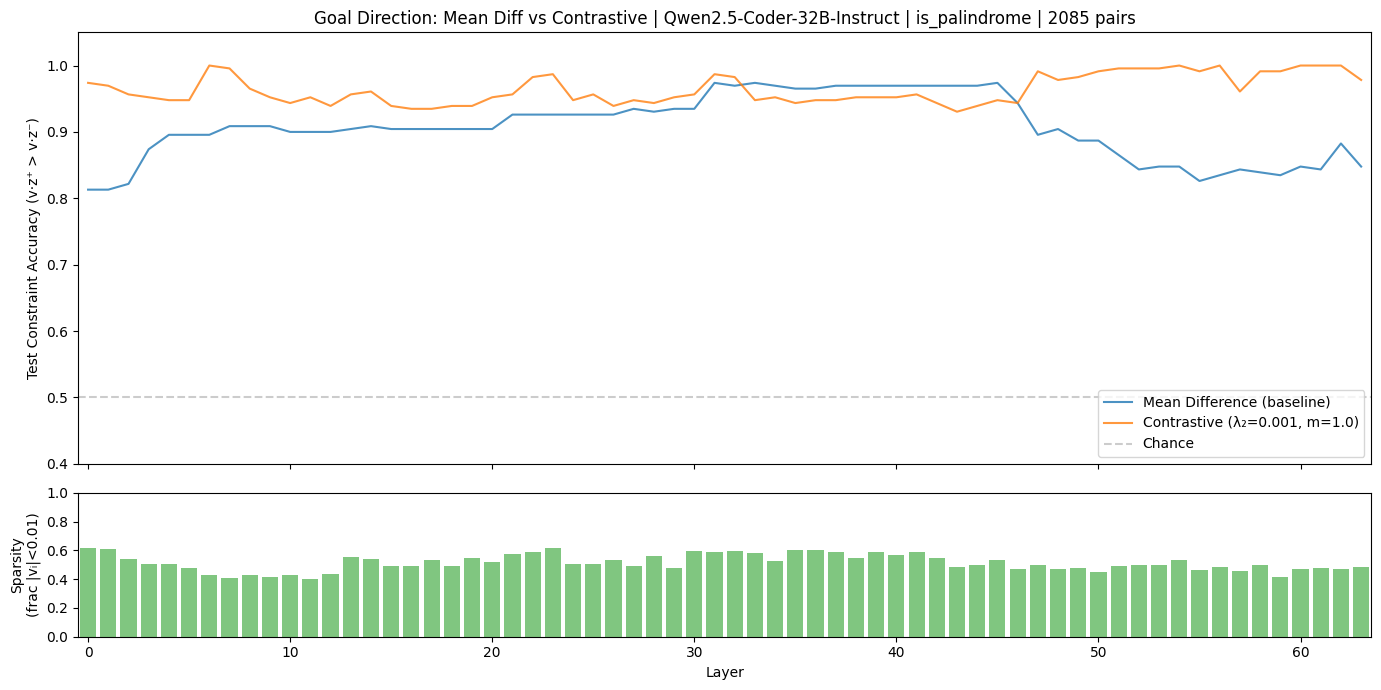

In [30]:
import matplotlib.pyplot as plt

layers_sorted = sorted(LAYERS_TO_PROBE)
md_test = [test_accuracies[l]           for l in layers_sorted]
ct_test = [contrastive_test_accs[l]     for l in layers_sorted]
ct_sparsity = [contrastive_infos[l]["sparsity"] for l in layers_sorted]
reg_label = ", ".join(reg_desc)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

ax = axes[0]
ax.plot(layers_sorted, md_test, label="Mean Difference (baseline)", alpha=0.8, linewidth=1.5)
ax.plot(layers_sorted, ct_test, label=f"Contrastive ({reg_label}, m={MARGIN})", alpha=0.8, linewidth=1.5)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_ylabel("Test Constraint Accuracy (v·z⁺ > v·z⁻)")
ax.set_title(
    f"Goal Direction: Mean Diff vs Contrastive | {model_tag} | "
    f"{target_predicate.name} | {n_pairs} pairs"
)
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.05)

ax2 = axes[1]
ax2.bar(layers_sorted, ct_sparsity, alpha=0.6, color="tab:green", width=0.8)
ax2.set_xlabel("Layer")
ax2.set_ylabel("Sparsity\n(frac |vᵢ|<0.01)")
ax2.set_ylim(0, 1)
ax2.set_xlim(layers_sorted[0] - 0.5, layers_sorted[-1] + 0.5)

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "direction_accuracy.png"), dpi=150)
plt.show()


### Save directions

In [31]:
torch.save(contrastive_directions, os.path.join(save_dir, "contrastive_directions.pt"))
torch.save(goal_directions,        os.path.join(save_dir, "mean_diff_directions.pt"))

with open(os.path.join(save_dir, "contrastive_infos.json"), "w") as f:
    json.dump(contrastive_infos, f, indent=2)

with open(os.path.join(save_dir, "test_accuracies.json"), "w") as f:
    json.dump({"mean_diff": test_accuracies, "contrastive": contrastive_test_accs}, f, indent=2)

rich_print(f"Saved directions to [bold]{save_dir}[/bold]")


Saved directions to /disk/u/arnab/Codes/Projects/goals/results/multipred_probe_test/Qwen2.5-Coder-32B-Instruct/is_palindrome

### Contrastive Direction Projection (Goal Axis + Residual PCA)

In [32]:
from sklearn.metrics import roc_auc_score

LAYER_FROM_CD = 0
LAYER_TO_CD   = mt.n_layer
LAYER_STEP_CD = 1
DO_NORMALIZE  = True

cd_layers = list(range(LAYER_FROM_CD, LAYER_TO_CD, LAYER_STEP_CD))
test_idx_arr = np.array(test_idx)

cd_proj_results: dict[int, dict] = {}

rich_print(f"\n{'Layer':>6} {'AUC(goal)':>10} {'AUC(resid)':>11} {'ResidVar%':>10}")
rich_print(f"{'-----':>6} {'---------':>10} {'----------':>11} {'---------':>10}")

for layer_idx in cd_layers:
    v = contrastive_directions[layer_idx].cpu().numpy()

    z_pos = Z_pos_by_layer[layer_idx][test_idx_arr].cpu().numpy()
    z_neg = Z_neg_by_layer[layer_idx][test_idx_arr].cpu().numpy()
    n_test = z_pos.shape[0]

    all_z = np.concatenate([z_pos, z_neg], axis=0)
    if DO_NORMALIZE:
        norms = np.maximum(np.linalg.norm(all_z, axis=1, keepdims=True), 1e-8)
        all_z = all_z / norms

    proj_goal = all_z @ v
    z_residual = all_z - np.outer(proj_goal, v)

    pca_res = PCA(n_components=1)
    proj_residual = pca_res.fit_transform(z_residual).squeeze()

    labels = np.concatenate([np.ones(n_test), np.zeros(n_test)])
    auc_goal  = roc_auc_score(labels, proj_goal)
    auc_resid = roc_auc_score(labels, proj_residual)

    cd_proj_results[layer_idx] = {
        "pos_goal":       proj_goal[:n_test],
        "neg_goal":       proj_goal[n_test:],
        "pos_residual":   proj_residual[:n_test],
        "neg_residual":   proj_residual[n_test:],
        "auc_goal":       auc_goal,
        "auc_residual":   auc_resid,
        "residual_var_ratio": pca_res.explained_variance_ratio_[0],
    }

    if layer_idx % 8 == 0:
        rich_print(f"{layer_idx:>6} {auc_goal:>10.4f} {auc_resid:>11.4f} {pca_res.explained_variance_ratio_[0]:>10.1%}")


Layer  AUC(goal)  AUC(resid)  ResidVar%

-----  ---------  ----------  ---------

0     0.9325      0.6370      16.8%

8     0.9804      0.7180      16.6%

16     0.9643      0.7586      13.8%

24     0.9834      0.8140      13.2%

32     0.9871      0.9108      13.6%

40     0.9792      0.8883      14.2%

48     0.9755      0.2737      13.6%

56     0.9670      0.5645      14.6%

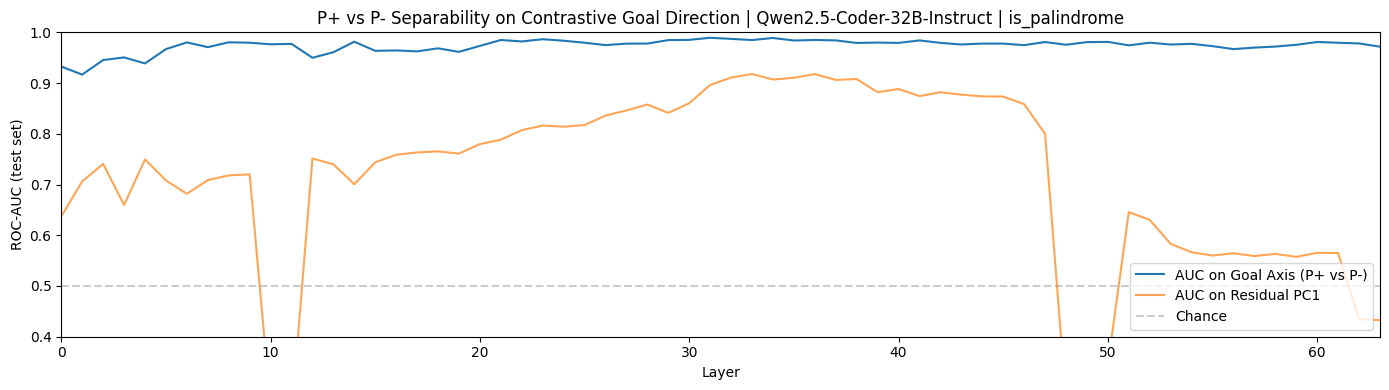

In [33]:
# ── AUC summary plot ──────────────────────────────────────────────────────────
layers_sorted_cd = sorted(cd_proj_results.keys())
auc_goal_vals  = [cd_proj_results[l]["auc_goal"]      for l in layers_sorted_cd]
auc_resid_vals = [cd_proj_results[l]["auc_residual"]  for l in layers_sorted_cd]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(layers_sorted_cd, auc_goal_vals,  label="AUC on Goal Axis (P+ vs P-)", linewidth=1.5)
ax.plot(layers_sorted_cd, auc_resid_vals, label="AUC on Residual PC1", linewidth=1.5, alpha=0.7)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_xlabel("Layer")
ax.set_ylabel("ROC-AUC (test set)")
ax.set_title(
    f"P+ vs P- Separability on Contrastive Goal Direction | "
    f"{mt.name.split('/')[-1]} | {target_predicate.name}"
)
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.0)
ax.set_xlim(layers_sorted_cd[0], layers_sorted_cd[-1])
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "auc_summary.png"), dpi=150)
plt.show()


In [35]:

from typing import Literal
from sklearn.metrics import roc_auc_score

# Project test-set latents onto:
#   X-axis: Learned direction v   (goal axis)
#   Y-axis: Top PCA component of the residual (z − (z·v)v)

DIRECTION_TYPE: Literal["contrastive", "mean_diff"] = "contrastive"
LAYER_STEP_ANIM = 4
DO_NORMALIZE = True

_dirs = contrastive_directions if DIRECTION_TYPE == "contrastive" else goal_directions
anim_layers = sorted(l for l in _dirs if l % LAYER_STEP_ANIM == 0)

# Recompute projections for the selected direction type
_proj: dict[int, dict] = {}
for l in anim_layers:
    v = _dirs[l].cpu().numpy()
    z_pos = Z_pos_by_layer[l][test_idx_arr].cpu().numpy()
    z_neg = Z_neg_by_layer[l][test_idx_arr].cpu().numpy()
    n_test = z_pos.shape[0]
    all_z = np.concatenate([z_pos, z_neg], axis=0)
    if DO_NORMALIZE:
        norms = np.maximum(np.linalg.norm(all_z, axis=1, keepdims=True), 1e-8)
        all_z = all_z / norms
    pg = all_z @ v
    zr = all_z - np.outer(pg, v)
    pr = PCA(n_components=1).fit_transform(zr).squeeze()
    labels = np.concatenate([np.ones(n_test), np.zeros(n_test)])
    _proj[l] = {
        "pos_goal":     pg[:n_test], "neg_goal":     pg[n_test:],
        "pos_residual": pr[:n_test], "neg_residual": pr[n_test:],
        "auc_goal":     roc_auc_score(labels, pg),
        "auc_residual": roc_auc_score(labels, pr),
    }

all_x = np.concatenate([np.concatenate([_proj[l]["pos_goal"],     _proj[l]["neg_goal"]])     for l in anim_layers])
all_y = np.concatenate([np.concatenate([_proj[l]["pos_residual"], _proj[l]["neg_residual"]]) for l in anim_layers])
pad_x = (all_x.max() - all_x.min()) * 0.05
pad_y = (all_y.max() - all_y.min()) * 0.05

fig, ax = plt.subplots(figsize=(8, 7))
neg_sc = ax.scatter([], [], alpha=0.25, s=8, c="tab:red",  label="P- (pursuing P−)")
pos_sc = ax.scatter([], [], alpha=0.25, s=8, c="tab:blue", label="P+ (pursuing P+)")
ax.legend(markerscale=4, loc="upper left")
ax.set_xlim(all_x.min() - pad_x, all_x.max() + pad_x)
ax.set_ylim(all_y.min() - pad_y, all_y.max() + pad_y)
ax.axvline(0, color="gray", linewidth=0.5, linestyle="--", alpha=0.4)
ax.axhline(0, color="gray", linewidth=0.5, linestyle="--", alpha=0.4)
ax.set_xlabel(f"Projection onto {DIRECTION_TYPE.replace('_', '-')} direction (v)")
ax.set_ylabel("Residual PC1  (z − (z·v)v)")
title = ax.set_title("")

def update(frame_idx):
    l = anim_layers[frame_idx]
    r = _proj[l]
    pos_sc.set_offsets(np.column_stack([r["pos_goal"], r["pos_residual"]]))
    neg_sc.set_offsets(np.column_stack([r["neg_goal"], r["neg_residual"]]))
    title.set_text(
        f"Layer {l} | {mt.name.split('/')[-1]} | {target_predicate.name} | {DIRECTION_TYPE}\n"
        f"AUC(goal)={r['auc_goal']:.3f}  AUC(resid)={r['auc_residual']:.3f}"
    )
    return pos_sc, neg_sc, title

anim2 = animation.FuncAnimation(fig, update, frames=len(anim_layers), interval=300, blit=False)
gif_name = f"goal_axis_residual_{DIRECTION_TYPE}.gif"
anim2.save(os.path.join(FIGURE_DIR, gif_name), writer="pillow", fps=2, dpi=120)
plt.close(fig)
rich_print(f"Saved [bold]{gif_name}[/bold] to {FIGURE_DIR}")
HTML(anim2.to_jshtml())


2026-03-03 13:41:36 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>


Saved goal_axis_residual_contrastive.gif to /disk/u/arnab/Codes/Projects/goals/results/multipred_probe_test/Qwen2.5-Coder-32B-Instruct/is_palindrome/figures

2026-03-03 13:41:39 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>
2026-03-03 13:41:39 matplotlib.animation DEBUG    frame size in pixels is 800 x 700
2026-03-03 13:41:41 matplotlib.animation DEBUG    MovieWriter: clearing temporary path=<TemporaryDirectory '/tmp/tmpsnuuyzas'>


## Test Causality (Steering)

Steer the model with the learned P+ direction and check whether it shifts generation
toward implementing P+ first.  Since all orderings are correct (green), we evaluate
by checking which predicate's anchor token appears first in the steered generation —
not by unit tests.

`coeff > 0` steers toward P+ first; `coeff < 0` steers toward P- first.

In [36]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.functional import generate_with_patch, get_hs, PatchSpec
from src.tokens import prepare_input

# ── Select sample + build prompt ─────────────────────────────────────────────
SAMPLE_IDX = 0
sample = target_predicate.samples[SAMPLE_IDX]

# Use an inconsequential (unprefilled) prompt to see the model's natural preference
prefill = ""
if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip() if hasattr(sample, "instruction") else "",
        incomplete_code=sample.code + prefill,
    )
else:
    prompt = sample.code + prefill

print(f'"Prompt (last 200 chars):\n...{prompt[-200:]}"')


"Prompt (last 200 chars):
...2 characters and is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_valid_palindrome(s: str) -> bool:
    """Return True iff s has at least 2 characters and is a palindrome."""
    return "


In [37]:
# ── Extract hidden state at last position for norm-scaling ───────────────────
tokenized = prepare_input(prompts=prompt, tokenizer=mt)
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(l), -1) for l in range(mt.n_layer)],
)


In [49]:
# ── Load directions + build steering patches ─────────────────────────────────
loaded_directions = torch.load(
    os.path.join(save_dir, "contrastive_directions.pt"),
    map_location="cuda:0",
)

# Steer layers where test accuracy is highest — inspect auc_summary.png to pick range
layer_from = 30
layer_to   = 40
coeff      = 0.04  # positive = toward P+; negative = toward P-

steer_patches = []
for layer_idx in range(layer_from, layer_to):
    layer_name = mt.layer_name_format.format(layer_idx)
    h_orig   = hs[(layer_name, -1)]
    goal_dir = loaded_directions[layer_idx].to(h_orig.device)
    scaled   = goal_dir * coeff * (h_orig.norm() / goal_dir.norm())
    steer_patches.append(
        PatchSpec(location=(layer_name, -1), patch=scaled, strategy="add", on_pass="all")
    )

rich_print(f"Steering layers {layer_from}–{layer_to - 1} with coeff={coeff}")


Steering layers 30–39 with coeff=0.04

In [50]:
from scripts.test_causality import generate_and_evaluate

# ── Generate baseline and steered outputs ────────────────────────────────────
N_GENERATIONS = 100
MAX_NEW_TOKENS = 64

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=100,
    patches = None,
    label = "testing"
)

2026-03-03 13:45:26 scripts.test_causality DEBUG    Generating 100 samples (testing)...


2026-03-03 13:45:33 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-03 13:45:33 scripts.test_causality DEBUG    Evaluation done: 100/100 passed (1.000)


In [51]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def is_valid_palindrome(s: str) -> bool:
    """Return True iff s has at least 2 characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
└───────────────────┴─────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 100/100 passed, 0/100 failed

In [52]:
steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=N_GENERATIONS,
    patches=steer_patches,
    label="steering"
)


2026-03-03 13:45:35 scripts.test_causality DEBUG    Generating 100 samples (steering)...


2026-03-03 13:45:43 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-03 13:45:43 scripts.test_causality DEBUG    Evaluation done: 100/100 passed (1.000)


In [53]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def is_valid_palindrome(s: str) -> bool:
    """Return True iff s has at least 2 characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
└───────────────────┴─────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 100/100 passed, 0/100 failed

In [54]:
# ── Evaluate: which predicate appears first? (anchor-token scoring) ───────────
from src.goals.anchor import _extract_boolean_expr, _split_clauses

baseline_outputs = [gen.lm_generation for gen in baseline_eval_results.generations]
steered_outputs = [gen.lm_generation for gen in steered_eval_results.generations]

p_plus_anchors = target_predicate.p_plus.anchor_tokens
p_minus_anchors = sample.p_minus.anchor_tokens if sample.p_minus else []


def predicate_order(text: str) -> str:
    """Return 'p_plus_first', 'p_minus_first', or 'unclear'."""
    full = sample.code + prefill + text
    result = _extract_boolean_expr(full)
    if result is None:
        # Fall back to raw anchor search
        p_plus_pos = min(
            (full.find(a) for a in p_plus_anchors if full.find(a) >= 0), default=None
        )
        p_minus_pos = min(
            (full.find(a) for a in p_minus_anchors if full.find(a) >= 0), default=None
        )
    else:
        expr, expr_start = result
        p_plus_pos = next(
            (expr.find(a) for a in p_plus_anchors if expr.find(a) >= 0), None
        )
        p_minus_pos = next(
            (expr.find(a) for a in p_minus_anchors if expr.find(a) >= 0), None
        )

    if p_plus_pos is None and p_minus_pos is None:
        return "unclear"
    if p_minus_pos is None:
        return "p_plus_first"
    if p_plus_pos is None:
        return "p_minus_first"
    return "p_plus_first" if p_plus_pos <= p_minus_pos else "p_minus_first"


from collections import Counter

baseline_orders = Counter(predicate_order(g) for g in baseline_outputs)
steered_orders = Counter(predicate_order(g) for g in steered_outputs)

rich_print(f"\nP+ anchors : {p_plus_anchors}")
rich_print(f"P- anchors : {p_minus_anchors}")
rich_print(f"\nBaseline predicate order: {dict(baseline_orders)}")
rich_print(f"Steered  predicate order: {dict(steered_orders)}")


def _rate(counter, key):
    total = sum(counter.values())
    return counter.get(key, 0) / total if total > 0 else 0.0


rich_print(
    f"\nP+ first rate: baseline={_rate(baseline_orders, 'p_plus_first'):.2f}  "
    f"steered={_rate(steered_orders, 'p_plus_first'):.2f}  "
    f"Δ={_rate(steered_orders, 'p_plus_first') - _rate(baseline_orders, 'p_plus_first'):+.2f}"
)


P+ anchors : ['::-1]', '== s.lower()[::-1]', '== s[', '== s[::-1]', '==s', '>> 1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s', 's != s[', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's.lower()[::-1]', 's[-(', 's[-1:-3:-1]', 's[-2:]', 
's[-i-1]', 's[::-', 's[::- 1]', 's[::-1]']

P- anchors : ['> 1', '>= 2', 'len(', 'len(s)']

Baseline predicate order: {'p_minus_first': 100}

Steered  predicate order: {'p_minus_first': 100}

P+ first rate: baseline=0.00  steered=0.00  Δ=+0.00

### Check goal persistance

In [76]:
from src.goals.data import IncompleteCodeDataset

single_pred_ds = IncompleteCodeDataset.load_dataset()
single_pred_idx = [
    idx
    for idx, single_sample in enumerate(single_pred_ds.samples)
    if single_sample.function_name == target_predicate.name
][0]
print(f"Selected sample idx: {single_pred_idx} / {len(single_pred_ds.samples)}")
single_pred_sample = single_pred_ds.samples[single_pred_idx]
print(f'"{single_pred_sample.code}"')


prefill = "(3"
# prefill = "0 =="
# prefill = "1 +"
# prefill = "1 -"
# prefill = "1 - len(s)"
# prefill = "1"
# prefill = ""
# prefill = "5"
# prefill = "("
# prefill = "3 +"

if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip(),
        incomplete_code=single_pred_sample.code + prefill,
    )
else:
    prompt = single_pred_sample.instruction + "<code>" + single_pred_sample.code + prefill

print(f"Prompt:\n{prompt}")

2026-03-03 13:50:28 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json
Selected sample idx: 5 / 14
"def is_palindrome(s: str) -> bool:
    return True if "
Prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if (3


In [77]:
tokenized = prepare_input(
    prompts=prompt,
    tokenizer=mt,
)

hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(layer_name, -1) for layer_name in mt.layer_names],
)

In [78]:
from scripts.test_causality import generate_and_evaluate

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=100,
    patches = None,
    label = "testing"
)

2026-03-03 13:50:29 scripts.test_causality DEBUG    Generating 100 samples (testing)...


2026-03-03 13:50:36 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-03 13:50:36 scripts.test_causality DEBUG    Evaluation done: 44/100 passed (0.440)


In [84]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                          Code Completion Results                                          
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill             ┃ Logic                                               ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "(3" │ "(3 * s == s + s[::-1] + s) else False"             │ PASSED  │            │      │
├─────────────────────┼─────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(3 * s == s[::-1] + s[::-1] + s[::-1]) else False" │ PASSED  │            │      │
├─────────────────────┼─────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(3 * s == s[::-1] + s + s[::-1]) else False"       │ PASSED  │            │      │
├─────────────────────┼─────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(3 * s == s[::-1] + s + s[::-1]) else False"       │ PASSED  │            │      │
├─────────────────────┼─────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(3 * s == s[::-1] + s + s[::-1]) else False"       │ PASSED  │            │      │
└─────────────────────┴─────────────────────────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 44/100 passed, 56/100 failed

In [80]:
# ── Load directions + build steering patches ─────────────────────────────────

model_short_name = mt.name.split("/")[-1]
# save_dir = os.path.join(
#     env_utils.DEFAULT_RESULTS_DIR,
#     ############################################################
#     # "multi_probe",
#     "probes_unique",
#     ############################################################
#     model_short_name,
#     f"sample_{single_pred_idx}",
# )

save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe_test",
    model_short_name,
    target_predicate.name
)

loaded_directions = torch.load(
    os.path.join(save_dir, "contrastive_directions.pt"),
    map_location="cuda:0",
)

# Steer layers where test accuracy is highest — inspect auc_summary.png to pick range
layer_from = 40
layer_to = 50
coeff = 0.04  # positive = toward P+; negative = toward P-

steer_patches = []
for layer_idx in range(layer_from, layer_to):
    layer_name = mt.layer_name_format.format(layer_idx)
    h_orig = hs[(layer_name, -1)]
    goal_dir = loaded_directions[layer_idx].to(h_orig.device)
    scaled = goal_dir * coeff * (h_orig.norm() / goal_dir.norm())

    print(
        f"layer={layer_idx} >> |h_orig|={h_orig.norm()}, |goal_dir|={goal_dir.norm()}, |scaled|={scaled.norm()}"
    )

    steer_patches.append(
        PatchSpec(
            location=(layer_name, -1), patch=scaled, strategy="add", on_pass="all"
        )
    )

rich_print(f"Steering layers {layer_from}–{layer_to - 1} with coeff={coeff}")


layer=40 >> |h_orig|=272.0, |goal_dir|=1.0, |scaled|=10.879999160766602
layer=41 >> |h_orig|=276.0, |goal_dir|=1.0, |scaled|=11.039999961853027
layer=42 >> |h_orig|=282.0, |goal_dir|=0.9999999403953552, |scaled|=11.280000686645508
layer=43 >> |h_orig|=284.0, |goal_dir|=1.0, |scaled|=11.359999656677246
layer=44 >> |h_orig|=292.0, |goal_dir|=1.0, |scaled|=11.679999351501465
layer=45 >> |h_orig|=294.0, |goal_dir|=0.9999999403953552, |scaled|=11.760000228881836
layer=46 >> |h_orig|=306.0, |goal_dir|=0.9999999403953552, |scaled|=12.239999771118164
layer=47 >> |h_orig|=336.0, |goal_dir|=0.9999999403953552, |scaled|=13.440000534057617
layer=48 >> |h_orig|=366.0, |goal_dir|=1.0, |scaled|=14.639999389648438
layer=49 >> |h_orig|=398.0, |goal_dir|=1.0, |scaled|=15.920000076293945


Steering layers 40–49 with coeff=0.04

In [81]:
from scripts.test_causality import generate_and_evaluate

steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=100,
    patches=steer_patches,
    label="testing",
)

2026-03-03 13:50:37 scripts.test_causality DEBUG    Generating 100 samples (testing)...


2026-03-03 13:50:44 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-03 13:50:44 scripts.test_causality DEBUG    Evaluation done: 60/100 passed (0.600)


In [83]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                               Code Completion Results                                                
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill             ┃ Logic                                                          ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "(3" │ "(3 * s == s[::-1] + s[::-1] + s[::-1]) else False"            │ PASSED  │            │      │
├─────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(32 > len(s) == 0 or s == s[::-1]) else False"                │ PASSED  │            │      │
├─────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(3 * s == s[::-1] + s[::-1] + s[::-1]) else False"            │ PASSED  │            │      │
├─────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(32 <= ord(c) <= 126 for c in s) and s == s[::-1] else False" │ PASSED  │            │      │
├─────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "(3" │ "(3 * s == s[::-1] + s[::-1] + s[::-1]) else False"            │ PASSED  │            │      │
└─────────────────────┴────────────────────────────────────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 60/100 passed, 40/100 failed